# Image Data Preparation — Vegetable Classification

## Objective
Prepare the Vegetable Image Dataset for a four-class image
classification task using TensorFlow/Keras.

## Selected classes
- Bean
- Bitter_Gourd
- Bottle_Gourd
- Brinjal

## Dataset partitions
- Training
- Validation
- Test

## Input configuration
- Image size: 224 × 224
- Color channels: RGB
- Batch size: 32
- Pixel normalization: [0, 1]

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

print("TensorFlow version:", tf.__version__)
print("Available devices:", tf.config.list_physical_devices())

TensorFlow version: 2.21.0
Available devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


In [4]:
# Project configuration
CLASSES = [
    "Bean",
    "Bitter_Gourd",
    "Bottle_Gourd",
    "Brinjal"
]

IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

# Dataset location relative to the project root
DATA_DIR = Path("data/Vegetables/Vegetable_Images")

TRAIN_DIR = DATA_DIR / "train"
VAL_DIR = DATA_DIR / "validation"
TEST_DIR = DATA_DIR / "test"

# Verify paths
for directory in [TRAIN_DIR, VAL_DIR, TEST_DIR]:
    if not directory.exists():
        for base in (Path.cwd(), *Path.cwd().parents):
            for train_path in base.glob("**/train"):
                if all((train_path / class_name).is_dir() for class_name in CLASSES):
                    DATA_DIR = train_path.parent
                    TRAIN_DIR = train_path

                    val_name = "validation" if (DATA_DIR / "validation").is_dir() else "val"
                    VAL_DIR = DATA_DIR / val_name
                    TEST_DIR = DATA_DIR / "test"
                    break
            if TRAIN_DIR.exists():
                break

        directory = {
            "train": TRAIN_DIR,
            "validation": VAL_DIR,
            "test": TEST_DIR,
        }[directory.name]

    assert directory.exists(), (
        f"Directory not found: {directory}. "
        f"Current working directory: {Path.cwd()}. "
        "Check that the dataset is downloaded and its path is correct."
    )

print("Dataset paths verified.")

Dataset paths verified.


In [5]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    class_names=CLASSES,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True,
    seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    class_names=CLASSES,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    class_names=CLASSES,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

print("Class mapping:", train_ds.class_names)

Found 4000 files belonging to 4 classes.
Found 800 files belonging to 4 classes.
Found 800 files belonging to 4 classes.
Class mapping: ['Bean', 'Bitter_Gourd', 'Bottle_Gourd', 'Brinjal']


In [6]:
def normalize_images(images, labels):
    images = tf.cast(images, tf.float32) / 255.0
    return images, labels


train_ds = train_ds.map(
    normalize_images,
    num_parallel_calls=tf.data.AUTOTUNE
)

val_ds = val_ds.map(
    normalize_images,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_ds = test_ds.map(
    normalize_images,
    num_parallel_calls=tf.data.AUTOTUNE
)

In [7]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(
    buffer_size=AUTOTUNE
)

val_ds = val_ds.prefetch(
    buffer_size=AUTOTUNE
)

test_ds = test_ds.prefetch(
    buffer_size=AUTOTUNE
)

In [8]:
images, labels = next(iter(train_ds))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

print("Minimum pixel value:", tf.reduce_min(images).numpy())
print("Maximum pixel value:", tf.reduce_max(images).numpy())
print("Data type:", images.dtype)

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Minimum pixel value: 0.0
Maximum pixel value: 1.0
Data type: <dtype: 'float32'>


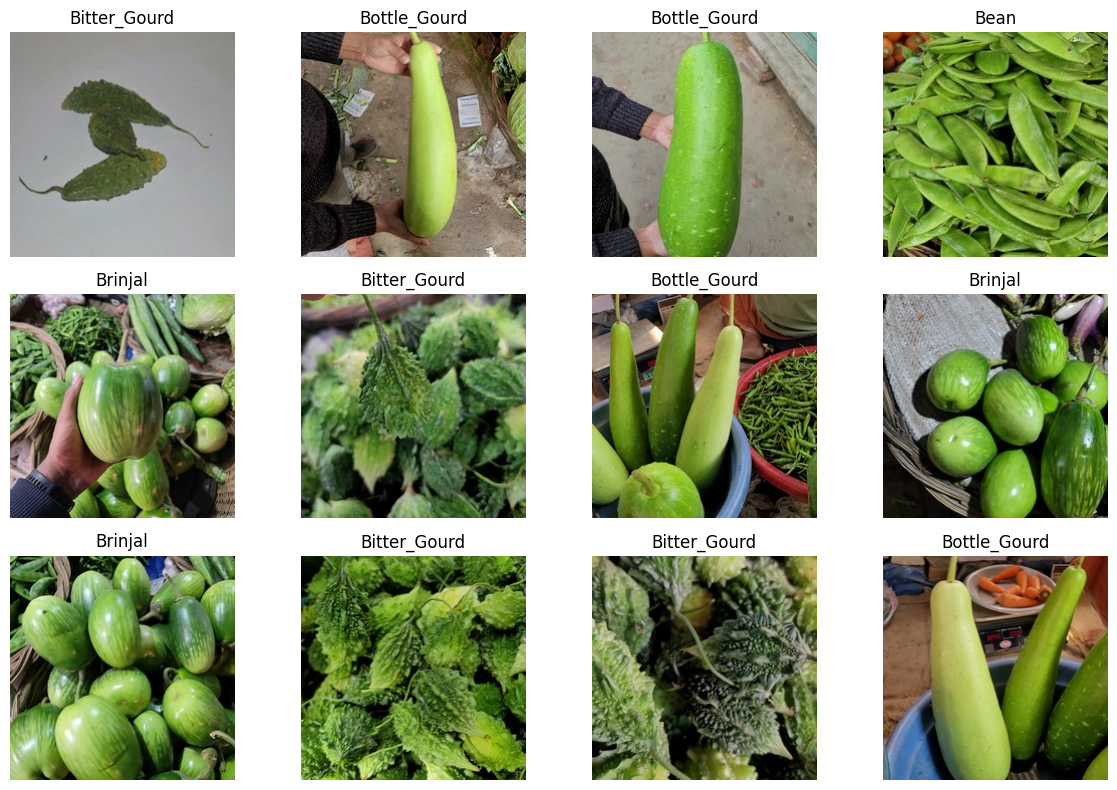

In [9]:
plt.figure(figsize=(12, 8))

for i in range(12):
    plt.subplot(3, 4, i + 1)

    plt.imshow(images[i].numpy())

    class_index = labels[i].numpy()
    class_name = CLASSES[class_index]

    plt.title(class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()